In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.preprocessing import StandardScaler, MinMaxScaler, FunctionTransformer

pd.set_option('display.max_rows', 50)
warnings.filterwarnings('ignore')

df = pd.read_csv('combined_OES_data.csv')
df.head()

,Date,Program Name,Grade,Mode,Burn,Fe,C,Si,Mn,P,...,ID 2,ID 3,Unnamed: 66,Unnamed: 68,Ni_lesser,Ni_greater,Unnamed: 65_lesser,Unnamed: 65_greater,Unnamed: 67_lesser,Unnamed: 67_greater
0,2022-04-28 10:40:58,FE_T_100,4_15,PA,1,98.5,0.173,0.221,0.579,0.0187,...,0,0,0.0,0.0,0,0,0,0,0,0
1,2022-04-28 10:40:58,FE_T_100,4_15,PA,2.0,98.5,0.174,0.218,0.579,0.0168,...,0,0,0.0,0.0,0,0,0,0,0,0
2,2022-04-28 10:40:58,FE_T_100,4_15,PA,3.0,98.5,0.178,0.221,0.587,0.0188,...,0,0,0.0,0.0,0,0,0,0,0,0
3,2022-04-28 09:36:35,FE_T_100,5_15,PA,1,97.8,0.135,0.265,0.703,0.0188,...,0,0,0.0,0.0,0,0,0,0,0,0
4,2022-04-28 09:36:35,FE_T_100,5_15,PA,2.0,97.8,0.135,0.262,0.704,0.0179,...,0,0,0.0,0.0,0,0,0,0,0,0


In [6]:
# Find rows where 'ID 1' contains an underscore
mask = df['ID 1'].str.contains('_')

# Swap 'ID 1' and 'Grade' values in these rows
df.loc[mask, ['ID 1', 'Grade']] = df.loc[mask, ['Grade', 'ID 1']].values

# FIXME?: keep lesser and greater?
# Identifying columns that contain 'lesser' or 'greater' in their names
columns_to_drop = [col for col in df.columns if 'lesser' in col or 'greater' in col or 'Unnamed' in col]

# FIXME?: keep ID 1 where typ of steel is present for future analysis 
# Adding specific columns to the list
additional_columns = ['Program Name', 'Mode', 'Burn', 'ID 1', 'ID 2', 'ID 3', 'Date']
columns_to_drop.extend(additional_columns)

# Ensuring only columns present in df are attempted to be dropped
columns_to_drop = [col for col in columns_to_drop if col in df.columns]

# Dropping these columns from the DataFrame
df = df.drop(columns=columns_to_drop)

# reduce the number of rows by removing every row without proper grade
df = df[df['Grade'].str.contains('_')]

# Define the condition for moving rows
condition = (df['Fe'] < 97.0) | (df['S'] > 0.09) | (df['Al'] > 0.075) | (df['Pb'] > 0.06)

# Create df_out with rows that match the condition
df_out = df[condition].copy()

# Add the 'Measuring error' column set to True
df_out['Measuring error'] = True

# Remove the rows from the original df
df = df[~condition]

In [7]:
# Lies die Daten aus der csv Datei ein
df_test = pd.read_csv('combined_OES_data.csv')

# Find rows where 'ID 1' contains an underscore
mask = df_test['ID 1'].str.contains('_')

# Swap 'ID 1' and 'Grade' values in these rows
df_test.loc[mask, ['ID 1', 'Grade']] = df_test.loc[mask, ['Grade', 'ID 1']].values

# Droppe alle Spalten die 'lesser', 'greater' oder 'Unnamed' im Namen haben
columns_to_drop_all = [col for col in df_test.columns if 'lesser' in col or 'greater' in col or 'Unnamed' in col]

# Entferne die Spalten aus der Liste
df_test = df_test.drop(columns=columns_to_drop_all)

# Finde die Werte in 'Grade' für Zeilen, die 'St' in 'ID 1' enthalten
grades_with_st = df_test[df_test['ID 1'].str.contains('St')]['Grade']

# Zeilen filtern, die entweder 'St' in 'ID 1' enthalten oder denselben 'Grade' Wert haben
df_test = df_test[df_test['ID 1'].str.contains('St') | df_test['Grade'].isin(grades_with_st)]

# Entfernen der Spalten 'Program Name', 'Mode', 'Burn', 'ID 2', 'ID 3', 'Date'
df_test = df_test.drop(columns=['Program Name', 'Mode', 'Burn', 'ID 2', 'ID 3', 'Date'])

# Alle 'St37' in 'ID 1' zu 'St 37' ändern
df_test['ID 1'] = df_test['ID 1'].replace('St37', 'St 37')

# Gruppieren der Daten nach 'Grade' und 'ID 1' und Berechnung des Mittelwerts
df_test = df_test.groupby(['Grade', 'ID 1']).mean()

# reset the index
df_test = df_test.reset_index()

# reduce the number of rows by removing every row without proper grade
df_test = df_test[df_test['Grade'].str.contains('_')]

# entferne Duplikate
df_test = df_test.drop_duplicates()

# entferne die Spalten 'Grade' und 'ID 1'
df_test1 = df_test.drop(columns=['Grade', 'ID 1'])

# save test data as csv
df_test.to_csv('test_data.csv', index=False)

df_test

,Grade,ID 1,Fe,C,Si,Mn,P,S,Cr,Mo,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
0,20_21_1,St 48,0.0,0.0331,0.204,0.701,0.0291,0.0295,0.0075,0.0051,...,0.0010,0.0020,0.04,0.0150,0.0080,0.001,0.0010,0.002,0.0507,0.0114
1,20_23_1,St 48,0.0,0.1620,0.130,0.720,0.0217,0.0411,0.0052,0.0041,...,0.0032,0.0018,0.04,0.0347,0.0122,0.001,0.0013,0.002,0.0629,0.0108
2,20_28_1,St 48,0.0,0.1440,0.265,0.600,0.0186,0.0261,0.0050,0.0049,...,0.0012,0.0018,0.04,0.0150,0.0191,0.001,0.0010,0.002,0.0638,0.0100
3,20_31_1,St 48,0.0,0.2640,0.274,0.627,0.0129,0.0312,0.0050,0.0049,...,0.0012,0.0023,0.04,0.0150,0.0089,0.001,0.0010,0.002,0.0353,0.0100
4,20_32_1,St 48,0.0,0.2550,0.288,0.643,0.0114,0.0577,0.0050,0.0040,...,0.0014,0.0023,0.04,0.0150,0.0106,0.001,0.0010,0.002,0.0444,0.0103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,S1_41_3_2,St 48-Th,0.0,0.2370,0.005,0.553,0.0489,0.0401,0.0050,0.0044,...,0.0010,0.0022,0.04,0.0150,0.0023,0.001,0.0010,0.002,0.0071,0.0171
258,S2_11_1_2,St 48-BK?,0.0,0.2250,0.005,0.429,0.0100,0.0305,0.0050,0.0042,...,0.0010,0.0015,0.04,0.0150,0.0081,0.001,0.0010,0.002,0.0311,0.0100
259,S2_11_2_2,St37-BK?,0.0,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128
260,S2_11_2_2,St48-BK?,0.0,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128


In [8]:
# Function to detect outliers in a Series
def find_outliers(series):
    Q1 = series.quantile(0.05)
    Q3 = series.quantile(0.95)
    IQR = Q3 - Q1
    return (series < (Q1 - 1.5 * IQR)) | (series > (Q3 + 1.5 * IQR))


# Apply the function to each column of df, except 'Grade'
outliers = df.drop(columns=['Grade']).apply(find_outliers)

# Any row with at least one outlier in the selected columns
rows_with_outliers = outliers.any(axis=1)

# Select rows containing outliers
new_outliers = df[rows_with_outliers].copy()

# Add the 'outlier' column set to True
new_outliers['outlier'] = True

# Append these rows to the existing df_out
df_out = pd.concat([df_out, new_outliers])

# Remove these rows from the original df
df = df[~rows_with_outliers]

print(new_outliers.describe())
df.describe()

               Fe           C          Si          Mn           P           S  \
count  210.000000  210.000000  210.000000  210.000000  210.000000  210.000000   
mean    98.229048    0.160288    0.347612    0.683076    0.032734    0.040130   
std      0.633864    0.092964    0.317573    0.253896    0.032091    0.016703   
min     97.000000    0.003000    0.005000    0.101000    0.003000    0.002000   
25%     97.800000    0.089200    0.061225    0.507000    0.014800    0.032200   
50%     98.200000    0.163500    0.278000    0.642000    0.022600    0.039700   
75%     98.800000    0.198750    0.503750    0.889000    0.036425    0.049375   
max     99.500000    0.651000    1.420000    1.240000    0.170000    0.089200   

               Cr          Mo          Ni          Al  ...          Ti  \
count  210.000000  210.000000  210.000000  210.000000  ...  210.000000   
mean     0.073683    0.004421    0.062170    0.017388  ...    0.002536   
std      0.125866    0.002306    0.060983    0.0

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,...,2664.000000,2664.000000,2.664000e+03,2.664000e+03,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000
mean,98.525713,0.189553,0.235680,0.597290,0.024310,0.037900,0.017854,0.004124,0.050551,0.004832,...,0.001586,0.002266,4.000000e-02,1.500000e-02,0.014689,0.001941,0.001172,0.002396,0.039367,0.017429
std,0.412965,0.082539,0.233178,0.146585,0.012037,0.013301,0.015693,0.001593,0.028168,0.007118,...,0.000658,0.000604,2.047358e-15,4.250870e-16,0.009596,0.000477,0.000276,0.000888,0.016321,0.007606
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
25%,98.300000,0.126000,0.011200,0.492000,0.015100,0.029200,0.007200,0.003000,0.034600,0.002000,...,0.001200,0.001875,4.000000e-02,1.500000e-02,0.007800,0.001600,0.001000,0.002000,0.027900,0.010000
50%,98.500000,0.207000,0.225000,0.599000,0.023000,0.037200,0.012200,0.003400,0.046800,0.002200,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.013600,0.001900,0.001100,0.002000,0.041100,0.016200
75%,98.800000,0.249000,0.270000,0.689000,0.031300,0.045700,0.022900,0.004800,0.055100,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018500,0.002200,0.001200,0.002000,0.050400,0.022800
max,99.500000,0.475000,1.320000,1.040000,0.090000,0.087500,0.110000,0.013700,0.199000,0.055600,...,0.006100,0.005900,4.000000e-02,1.500000e-02,0.067700,0.004200,0.003200,0.007100,0.125000,0.052600


In [9]:
# Remove duplicates
df = df.drop_duplicates()

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,...,2160.000000,2160.000000,2.160000e+03,2.160000e+03,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,98.527685,0.192527,0.231853,0.597188,0.024933,0.038230,0.017751,0.004115,0.049813,0.004606,...,0.001589,0.002275,4.000000e-02,1.500000e-02,0.014517,0.001958,0.001172,0.002398,0.040271,0.017725
std,0.402473,0.080610,0.221696,0.144899,0.012107,0.012990,0.015253,0.001593,0.026715,0.006418,...,0.000659,0.000586,1.068837e-15,3.921383e-16,0.008969,0.000471,0.000277,0.000889,0.015680,0.007679
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.600000,0.025400,0.005000,0.284590,0.005359,0.012318,0.005000,0.003000,0.016159,0.002000,...,0.001000,0.001159,4.000000e-02,1.500000e-02,0.002000,0.001000,0.001000,0.002000,0.004000,0.010000
5%,97.800000,0.043000,0.005000,0.373000,0.008600,0.017995,0.005000,0.003000,0.022500,0.002000,...,0.001000,0.001500,4.000000e-02,1.500000e-02,0.002700,0.001300,0.001000,0.002000,0.013400,0.010000
25%,98.300000,0.132000,0.082450,0.494000,0.015900,0.029800,0.007500,0.003000,0.034600,0.002000,...,0.001200,0.001900,4.000000e-02,1.500000e-02,0.008000,0.001600,0.001000,0.002000,0.029875,0.010000
50%,98.500000,0.210000,0.225000,0.596000,0.023400,0.037600,0.012400,0.003400,0.046200,0.002300,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.014000,0.001900,0.001100,0.002000,0.041900,0.016700
75%,98.800000,0.250000,0.270000,0.690250,0.031800,0.045800,0.022625,0.004800,0.054925,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018400,0.002200,0.001200,0.002000,0.050800,0.023100
95%,99.200000,0.304000,0.844000,0.841000,0.046600,0.061500,0.051000,0.007000,0.108050,0.017205,...,0.003100,0.003300,4.000000e-02,1.500000e-02,0.030705,0.002800,0.001700,0.004600,0.064000,0.030905


In [10]:
# TODO: find measuring errors and remove them
# FIXME?: remove rows with 'nan' or 0 values in column 'Grade'
# FIXME?: don't group by grade and take the mean
# merge the rows with the same grade
df = df.groupby('Grade').mean()

# reset the index
df = df.reset_index()

# Drop the 'Grade' column
df = df.drop(columns=['Grade'])

df_out = df_out.reset_index()
df_out = df_out.drop(columns=['index'])

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,...,407.000000,407.000000,4.070000e+02,4.070000e+02,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000
mean,98.528358,0.195502,0.235124,0.594342,0.024793,0.038842,0.016987,0.004119,0.049039,0.004819,...,0.001624,0.002267,4.000000e-02,1.500000e-02,0.014305,0.001957,0.001178,0.002397,0.039841,0.017518
std,0.401253,0.081389,0.221227,0.147132,0.012246,0.012922,0.014826,0.001587,0.026267,0.006438,...,0.000686,0.000598,4.168460e-16,8.339939e-17,0.008871,0.000437,0.000271,0.000646,0.015674,0.006822
min,97.300000,0.003933,0.005000,0.055800,0.003000,0.002000,0.005000,0.003000,0.011583,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.562400,0.019077,0.005000,0.266160,0.005357,0.004694,0.005000,0.003000,0.015918,0.002000,...,0.001000,0.001162,4.000000e-02,1.500000e-02,0.002000,0.001068,0.000060,0.002000,0.000240,0.000600
5%,97.800000,0.042159,0.005000,0.366933,0.008457,0.018400,0.005000,0.003000,0.021965,0.002000,...,0.001017,0.001524,4.000000e-02,1.500000e-02,0.002677,0.001288,0.001000,0.002000,0.012692,0.010000
25%,98.300000,0.136417,0.104417,0.494750,0.015875,0.030842,0.006992,0.003017,0.033775,0.002000,...,0.001200,0.001854,4.000000e-02,1.500000e-02,0.007775,0.001667,0.001017,0.002000,0.029192,0.011350
50%,98.483333,0.213333,0.226667,0.588500,0.023317,0.038617,0.012000,0.003600,0.045350,0.002640,...,0.001450,0.002167,4.000000e-02,1.500000e-02,0.013650,0.001933,0.001100,0.002017,0.041500,0.017000
75%,98.708333,0.252750,0.272583,0.692694,0.031233,0.047225,0.021125,0.004567,0.054875,0.004275,...,0.001733,0.002583,4.000000e-02,1.500000e-02,0.018117,0.002217,0.001250,0.002542,0.050900,0.021717
95%,99.200000,0.309400,0.843900,0.843933,0.046963,0.060663,0.048157,0.006747,0.092439,0.017362,...,0.003207,0.003245,4.000000e-02,1.500000e-02,0.030215,0.002785,0.001667,0.003731,0.063535,0.028872


In [20]:
# Auswählen der Spalten, die skaliert werden sollen
columns_to_scale = ['Fe', 'C', 'Si', 'Mn', 'P', 'S', 'Cr', 'Mo', 'Ni', 'Al', 'Co', 'Cu', 'Nb', 'Ti', 'V', 'W', 'Pb', 'Sn', 'B', 'Ca', 'Zr', 'As', 'Bi']

# Entferne Zeilen, bei denen in 'ID 1' ein '?' vorkommt
# df_test = df_test.loc[~df_test['ID 1'].str.contains('\?', na=False)]

# Skalieren der ausgewählten Spalten
scaler = FunctionTransformer(np.log1p, validate=True)
scaled_data = scaler.fit_transform(df_test[columns_to_scale])

# Erstellen eines neuen DataFrame für die skalierten Daten
df_scaled = pd.DataFrame(scaled_data, columns=columns_to_scale)
df_scaled

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
0,0.0,0.032564,0.185649,0.531216,0.028685,0.029073,0.007472,0.005087,0.033725,0.001998,...,0.001000,0.001998,0.039221,0.014889,0.007968,0.001,0.001000,0.001998,0.049457,0.011336
1,0.0,0.150143,0.122218,0.542324,0.021468,0.040278,0.005187,0.004092,0.038259,0.017152,...,0.003195,0.001798,0.039221,0.034112,0.012126,0.001,0.001299,0.001998,0.061001,0.010742
2,0.0,0.134531,0.235072,0.470004,0.018429,0.025765,0.004988,0.004888,0.043730,0.002497,...,0.001199,0.001798,0.039221,0.014889,0.018920,0.001,0.001000,0.001998,0.061847,0.009950
3,0.0,0.234281,0.242162,0.486738,0.012818,0.030723,0.004988,0.004888,0.038836,0.002297,...,0.001199,0.002297,0.039221,0.014889,0.008861,0.001,0.001000,0.001998,0.034691,0.009950
4,0.0,0.227136,0.253091,0.496524,0.011336,0.056097,0.004988,0.003992,0.026934,0.002297,...,0.001399,0.002297,0.039221,0.014889,0.010544,0.001,0.001000,0.001998,0.043443,0.010247
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,0.0,0.212689,0.004988,0.440189,0.047742,0.039317,0.004988,0.004390,0.026934,0.012423,...,0.001000,0.002198,0.039221,0.014889,0.002297,0.001,0.001000,0.001998,0.007075,0.016955
258,0.0,0.202941,0.004988,0.356975,0.009950,0.030044,0.004988,0.004191,0.058175,0.001998,...,0.001000,0.001499,0.039221,0.014889,0.008067,0.001,0.001000,0.001998,0.030626,0.009950
259,0.0,0.172271,0.004988,0.351361,0.010049,0.026155,0.004988,0.004092,0.056947,0.001998,...,0.001000,0.001699,0.039221,0.014889,0.008167,0.001,0.001000,0.001998,0.028199,0.012719
260,0.0,0.172271,0.004988,0.351361,0.010049,0.026155,0.004988,0.004092,0.056947,0.001998,...,0.001000,0.001699,0.039221,0.014889,0.008167,0.001,0.001000,0.001998,0.028199,0.012719


# T-SNE

In [27]:
from sklearn.manifold import TSNE
from mpl_toolkits.mplot3d import Axes3D
import plotly.express as px

In [31]:
def perplexity_analysis(data,start,end,steps):
    #gibt and mit wie vielen Punkten jeder Datenpunkt verglichen wird, muss kleiner sein als Anzahl der Datenpunkte (also max. n-1)

    perplexity = np.arange(start, end, steps)
    divergence = []

    for i in perplexity:
        model = TSNE(n_components=2, perplexity=i)
        reduced = model.fit_transform(df_scaled)
        divergence.append(model.kl_divergence_)
    fig = px.line(x=perplexity, y=divergence, markers=True)
    fig.update_layout(xaxis_title="Perplexity Values", yaxis_title="Divergence")
    fig.update_traces(line_color="red", line_width=1)
    fig.show()
    print("umso geringer der Wert von Divergence desto besser, optimal ist der Perplexity Wert wo es konstant wird")

In [32]:
perplexity_analysis(df_scaled,1,260,25)

umso geringer der Wert von Divergence desto besser, optimal ist der Perplexity Wert wo es konstant wird


In [24]:
def t_sne(data,perplexity):
        
    #2D
    tsne = TSNE(n_components=2, perplexity=perplexity, n_iter=1000, random_state=0)
    tsne_results = tsne.fit_transform(df_scaled)

    plt.figure(figsize=(10, 6))
    plt.scatter(tsne_results[:, 0], tsne_results[:, 1])
    plt.xlabel('t-SNE feature 1')
    plt.ylabel('t-SNE feature 2')
    plt.title('2D t-SNE Visualization')
    plt.show()
    
    #3D
    tsne = TSNE(n_components=3, perplexity=perplexity, n_iter=1000, random_state=0)
    df_tsne_3d = tsne.fit_transform(df_scaled)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(df_tsne_3d[:, 0], df_tsne_3d[:, 1], df_tsne_3d[:, 2])
    ax.set_xlabel('t-SNE Feature 1')
    ax.set_ylabel('t-SNE Feature 2')
    ax.set_zlabel('t-SNE Feature 3')
    plt.title('3D t-SNE Visualization')
    plt.show()
    

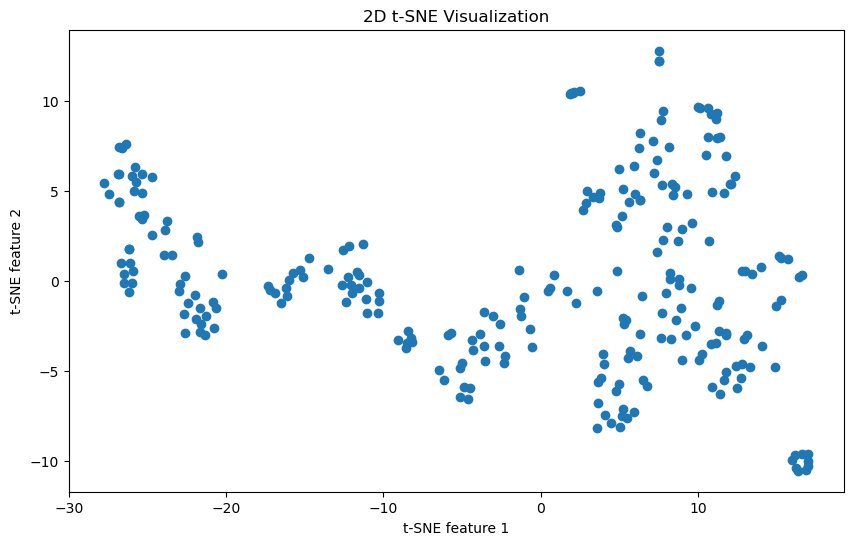

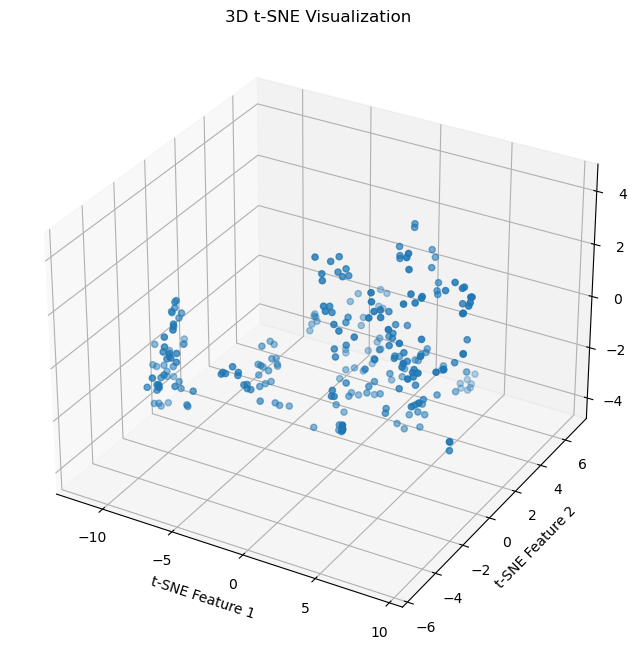

In [25]:
t_sne(df_scaled,30)